In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

# Cargar el dataset de características extraídas
df = pd.read_csv('../data/features_mafaulda.csv')

# Revisar la estructura y los primeros registros
display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 1951 entries, 0 to 1950
Data columns (total 69 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   file                               1951 non-null   str    
 1   filepath                           1951 non-null   str    
 2   nominal_frequency_hz               1951 non-null   float64
 3   nominal_speed_rpm                  1951 non-null   float64
 4   fault_family                       1951 non-null   str    
 5   fault_type                         1951 non-null   str    
 6   severity                           1951 non-null   float64
 7   severity_unit                      1902 non-null   str    
 8   bearing_position                   1071 non-null   str    
 9   underhang_axial_mean               1951 non-null   float64
 10  underhang_axial_std                1951 non-null   float64
 11  underhang_axial_rms                1951 non-null   float64
 12  und

None

,file,filepath,nominal_frequency_hz,nominal_speed_rpm,fault_family,fault_type,severity,severity_unit,bearing_position,underhang_axial_mean,...,overhang_tangential_mean,overhang_tangential_std,overhang_tangential_rms,overhang_tangential_min,overhang_tangential_max,overhang_tangential_peak_to_peak,overhang_tangential_peak,overhang_tangential_skewness,overhang_tangential_kurtosis,overhang_tangential_crest_factor
0,12.288.csv,F:\PROYECTO_DESPLIEGUE\dsa-fallas-maquinaria\d...,12.2880,737.280,horizontal-misalignment,horizontal_misalignment,0.5,mm,NaN,0.010533,...,0.002572,0.433117,0.433125,-1.04860,1.48930,2.53790,1.48930,0.311357,-0.550439,3.438503
1,13.5168.csv,F:\PROYECTO_DESPLIEGUE\dsa-fallas-maquinaria\d...,13.5168,811.008,horizontal-misalignment,horizontal_misalignment,0.5,mm,NaN,0.040608,...,0.013521,0.282465,0.282789,-0.83902,0.95026,1.78928,0.95026,0.060141,-0.573863,3.360319
2,14.5408.csv,F:\PROYECTO_DESPLIEGUE\dsa-fallas-maquinaria\d...,14.5408,872.448,horizontal-misalignment,horizontal_misalignment,0.5,mm,NaN,0.030728,...,0.011544,0.212980,0.213293,-0.77508,0.80139,1.57647,0.80139,0.211073,-0.150843,3.757230
3,15.36.csv,F:\PROYECTO_DESPLIEGUE\dsa-fallas-maquinaria\d...,15.3600,921.600,horizontal-misalignment,horizontal_misalignment,0.5,mm,NaN,0.002373,...,-0.018487,0.214210,0.215006,-0.78764,0.82364,1.61128,0.82364,0.247251,-0.180563,3.830778
4,16.384.csv,F:\PROYECTO_DESPLIEGUE\dsa-fallas-maquinaria\d...,16.3840,983.040,horizontal-misalignment,horizontal_misalignment,0.5,mm,NaN,0.004265,...,0.003175,0.258655,0.258675,-0.93933,0.89913,1.83846,0.93933,-0.024232,-0.292380,3.631315


### Auditoría de Datos
El dataset extraído consta de 1.951 observaciones y 69 características. Todas las variables estadísticas calculadas sobre las señales (RMS, media, kurtosis, etc.) se cargaron correctamente como valores numéricos (`float64`). 
Se identifican valores nulos únicamente en variables descriptivas secundarias: `severity_unit` (49 nulos) y `bearing_position` (880 nulos). Las variables predictoras no presentan datos faltantes, lo que permite avanzar sin necesidad de imputaciones complejas en las señales de vibración.

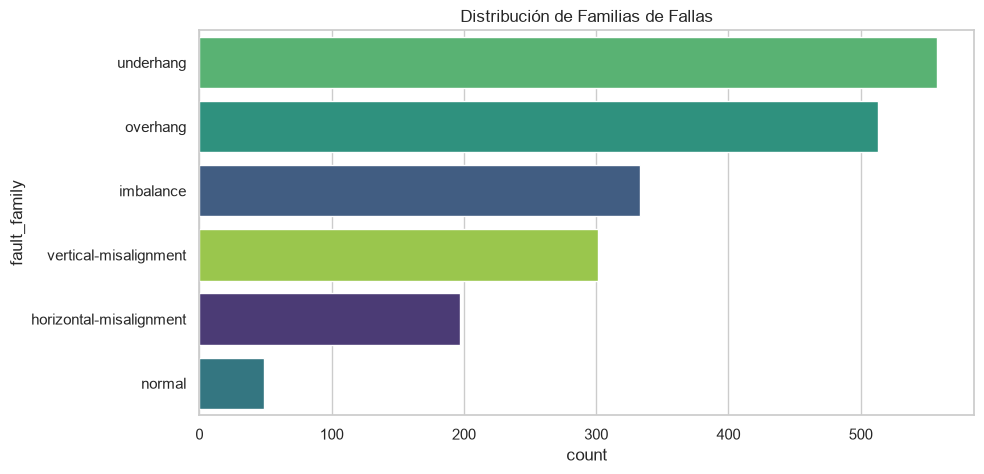

In [3]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='fault_family', order=df['fault_family'].value_counts().index, hue='fault_family', palette='viridis', legend=False)
plt.title('Distribución de Familias de Fallas')
plt.show()

### Balance de Clases
La distribución de la variable objetivo (`fault_family`) presenta un desbalance significativo. Las clases mayoritarias son las fallas asociadas a `underhang` y `overhang`, concentrando más del 50% de los registros. Por el contrario, el estado `normal` de la maquinaria es la clase minoritaria con aproximadamente 50 muestras. 
**Implicación para el modelado:** Será necesario aplicar técnicas de estratificación al dividir el set de datos (Train/Test) y evaluar el uso de métricas como el F1-Score Macro o técnicas de sobremuestreo (ej. SMOTE) para evitar que el modelo se sesgue hacia las fallas mayoritarias.

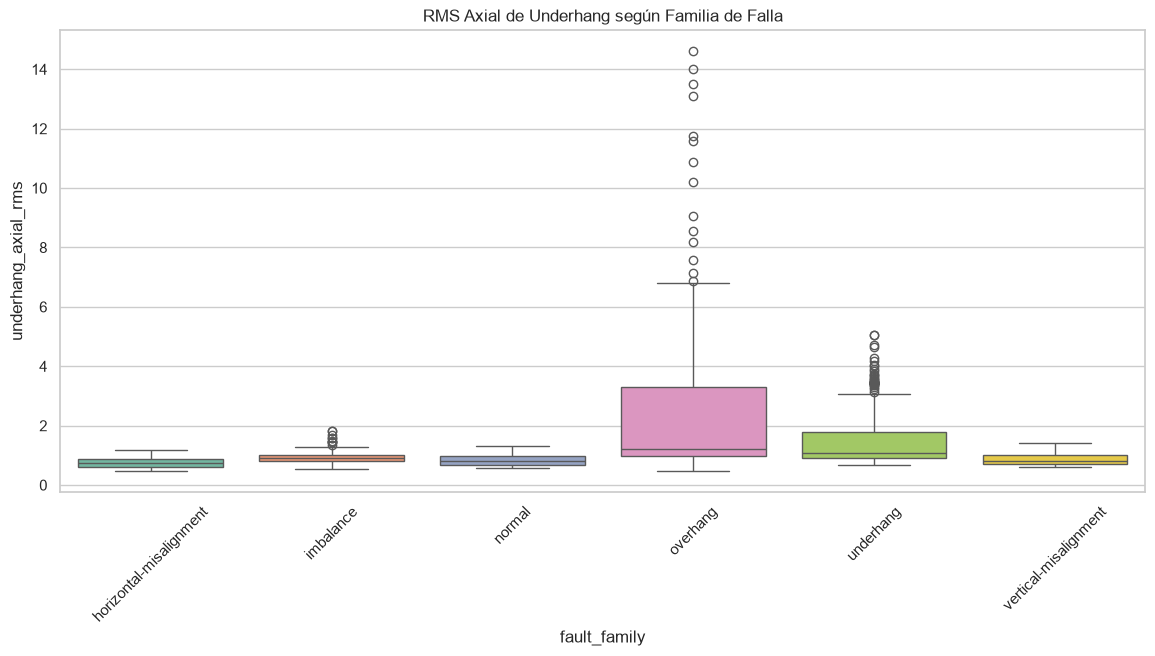

In [4]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='fault_family', y='underhang_axial_rms', hue='fault_family', palette='Set2', legend=False)
plt.title('RMS Axial de Underhang según Familia de Falla')
plt.xticks(rotation=45)
plt.show()

### Análisis Bivariado: Energía de Vibración vs. Falla
Al analizar la raíz cuadrática media (RMS) de la vibración axial en la zona de *underhang*, se observa un comportamiento diferenciado según el estado de la máquina. Las fallas de tipo `overhang` presentan la mayor dispersión de energía y una cantidad extrema de valores atípicos (outliers), superando valores de 14 en RMS. En contraste, el estado `normal`, el desbalanceo y las desalineaciones mantienen una varianza muy reducida y valores medianos cercanos a 1. 
Esto indica que las características estadísticas de dominio temporal tienen un alto poder discriminatorio para fallas severas, pero podrían tener dificultades para separar anomalías sutiles sin ayuda de otras variables.

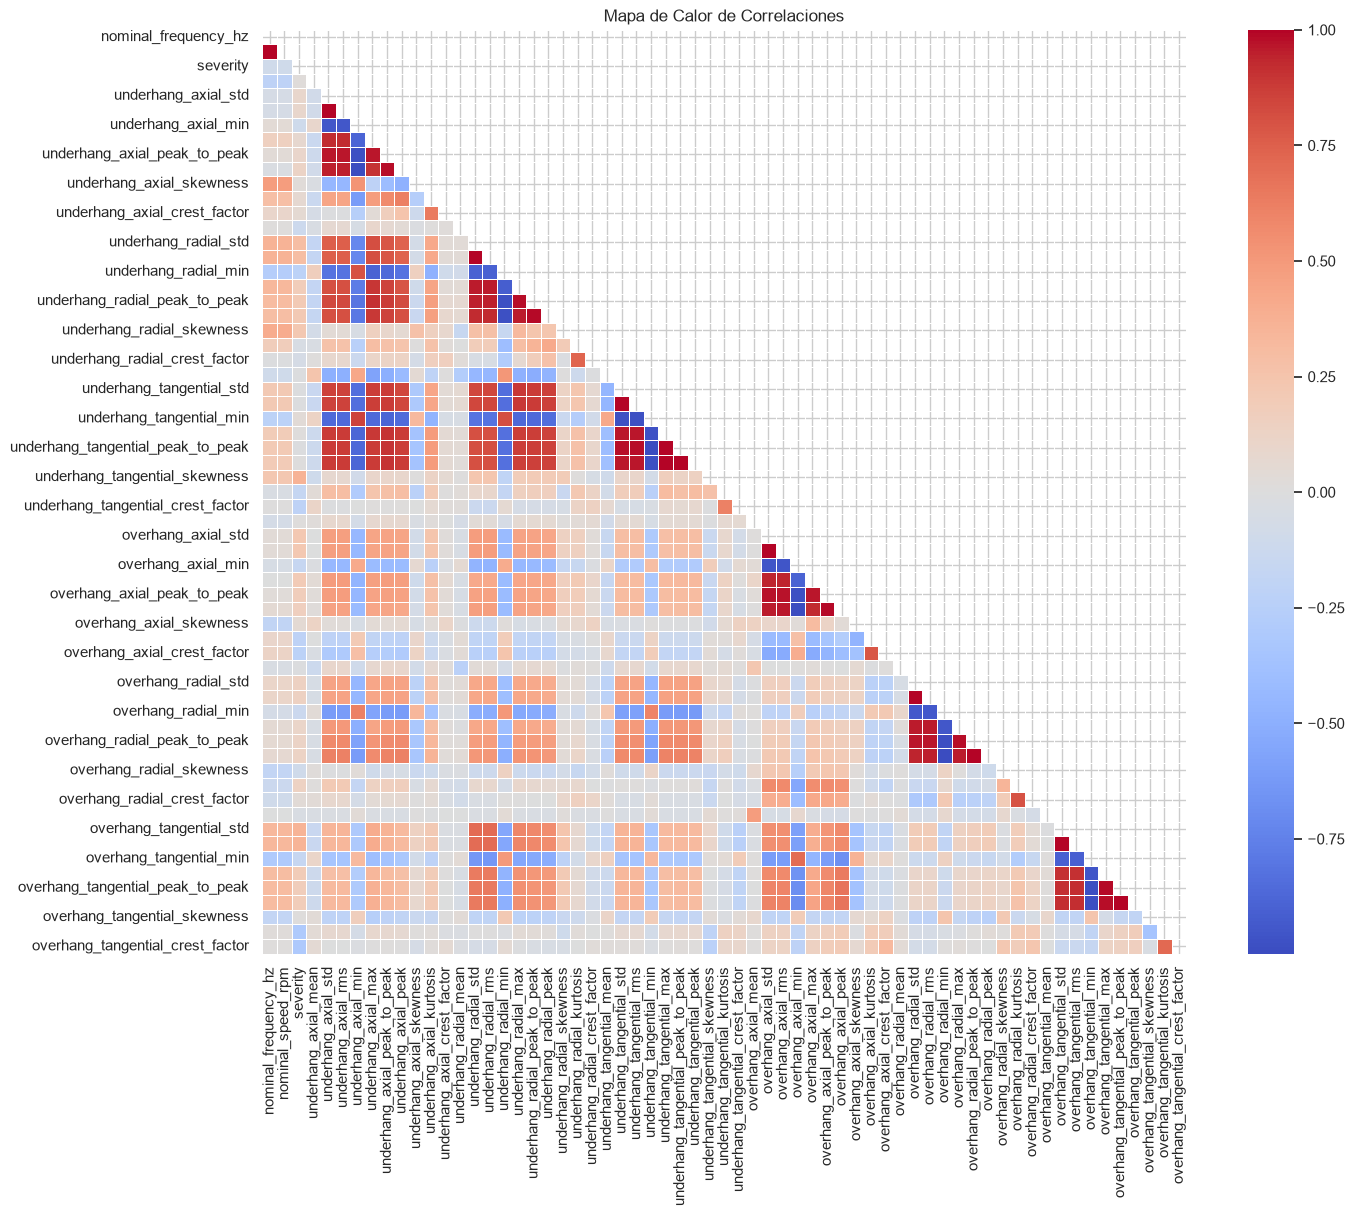

In [5]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 12))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, square=True, linewidths=.5)
plt.title('Mapa de Calor de Correlaciones')
plt.show()

###  Análisis Multivariado: Colinealidad
El mapa de correlación revela la existencia de bloques fuertemente interrelacionados (cuadros de color rojo intenso y azul oscuro). Las medidas estadísticas extraídas de una misma señal (por ejemplo, el valor máximo, el pico, el pico a pico y la desviación estándar) muestran correlaciones positivas cercanas a 1.0. 
**Implicación para el modelado:** Existe una alta redundancia en la información (colinealidad). Para evitar el sobreajuste (overfitting) y optimizar el costo computacional de los modelos predictivos, es altamente recomendable aplicar técnicas de selección de características (Feature Selection) o reducción de dimensionalidad antes del entrenamiento.

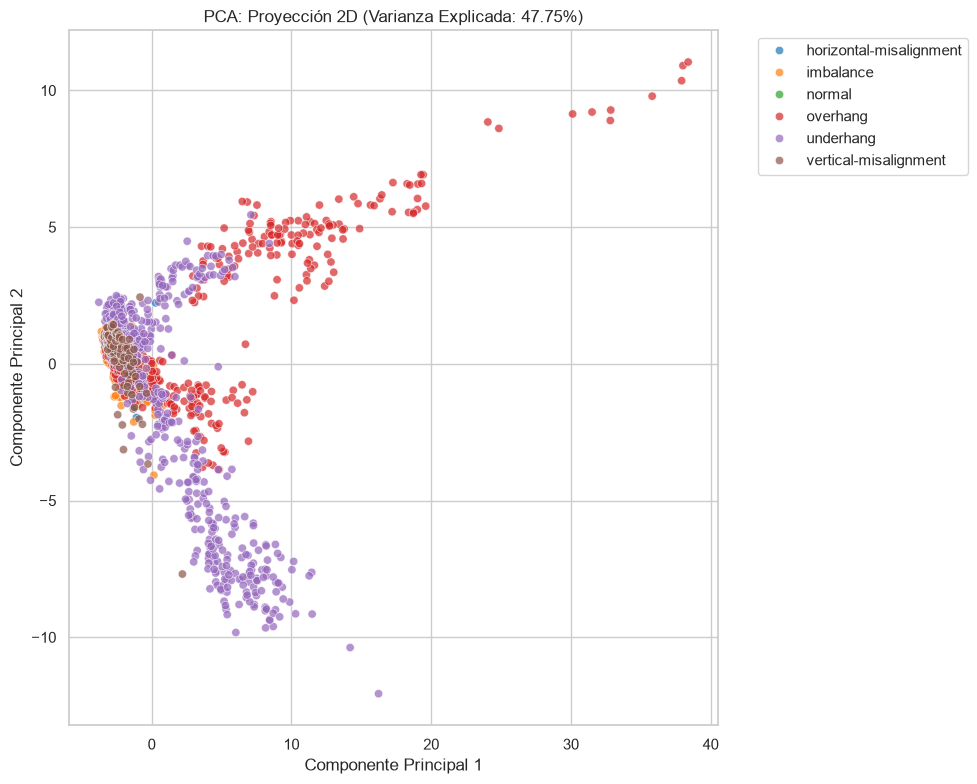

In [ ]:

# Imputar nulos numéricos (si los hay) y separar características
X = numeric_df.fillna(numeric_df.mean())
y = df['fault_family']

# Estandarizar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Graficar
plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y, palette='tab10', alpha=0.7)
plt.title(f'PCA: Proyección 2D (Varianza Explicada: {sum(pca.explained_variance_ratio_):.2%})')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Reducción de Dimensionalidad (PCA)
La proyección en 2 componentes principales (PCA) logra retener el 47.75% de la varianza total de las 69 características numéricas. Visualmente, el espacio 2D permite separar con claridad gran parte de las muestras de `overhang` y `underhang`, que se alejan del origen.
Sin embargo, existe un denso solapamiento cerca de las coordenadas (0,0) entre las clases `normal`, `imbalance` y las desalineaciones (`vertical-misalignment`, `horizontal-misalignment`). Esto confirma que una reducción a solo 2 dimensiones no es suficiente para capturar las diferencias sutiles entre estas fallas, justificando el uso de modelos multivariados no lineales (como Random Forest o SVM) y la retención de un mayor número de componentes si se opta por PCA en el pipeline final.

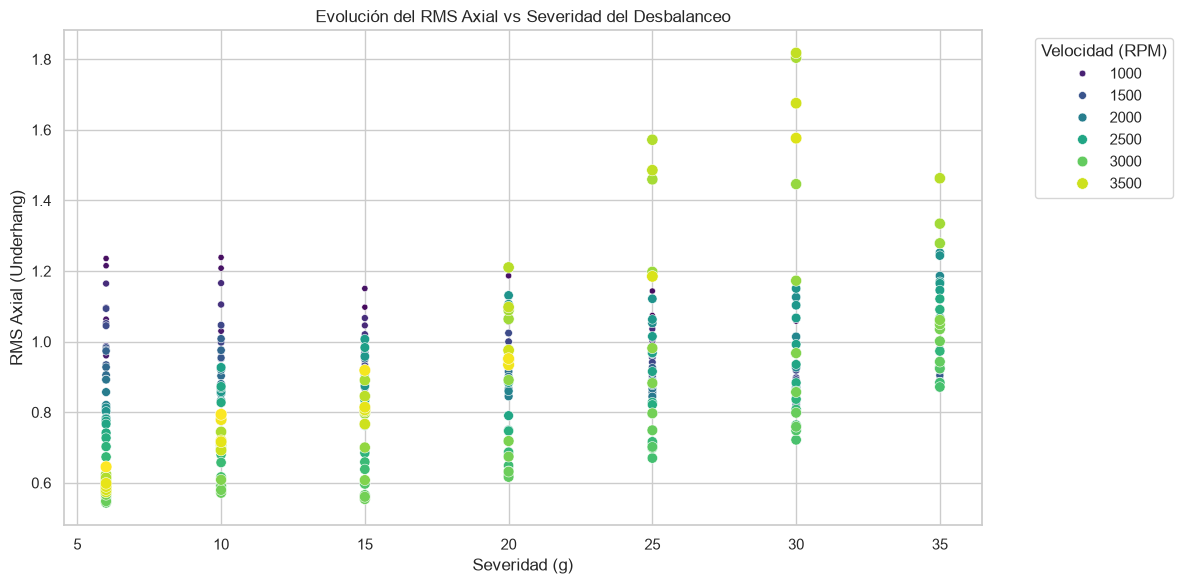

In [7]:
# Filtrar solo las fallas de desbalanceo para ver su progresión
imbalance_df = df[df['fault_family'] == 'imbalance'].copy()

# Convertir severidad a numérico si no lo está (manejando posibles strings)
imbalance_df['severity'] = pd.to_numeric(imbalance_df['severity'], errors='coerce')

plt.figure(figsize=(12, 6))
sns.scatterplot(data=imbalance_df, x='severity', y='underhang_axial_rms', hue='nominal_speed_rpm', palette='viridis', size='nominal_speed_rpm')
plt.title('Evolución del RMS Axial vs Severidad del Desbalanceo')
plt.xlabel('Severidad (g)')
plt.ylabel('RMS Axial (Underhang)')
plt.legend(title='Velocidad (RPM)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Análisis de Severidad (Desbalanceo)
La energía de vibración (RMS) no escala linealmente solo con la masa del desbalanceo (severidad en gramos). El gráfico demuestra que existe una fuerte interacción con la velocidad operativa: a bajas revoluciones (1000 RPM) el impacto de aumentar la masa de desbalanceo es mínimo o nulo. No obstante, a 3500 RPM, masas superiores a 20g causan incrementos severos en la vibración. Esto confirma que la variable `nominal_speed_rpm` será indispensable para que el modelo interprete correctamente la gravedad de una anomalía, ya que actúa como un amplificador del daño.

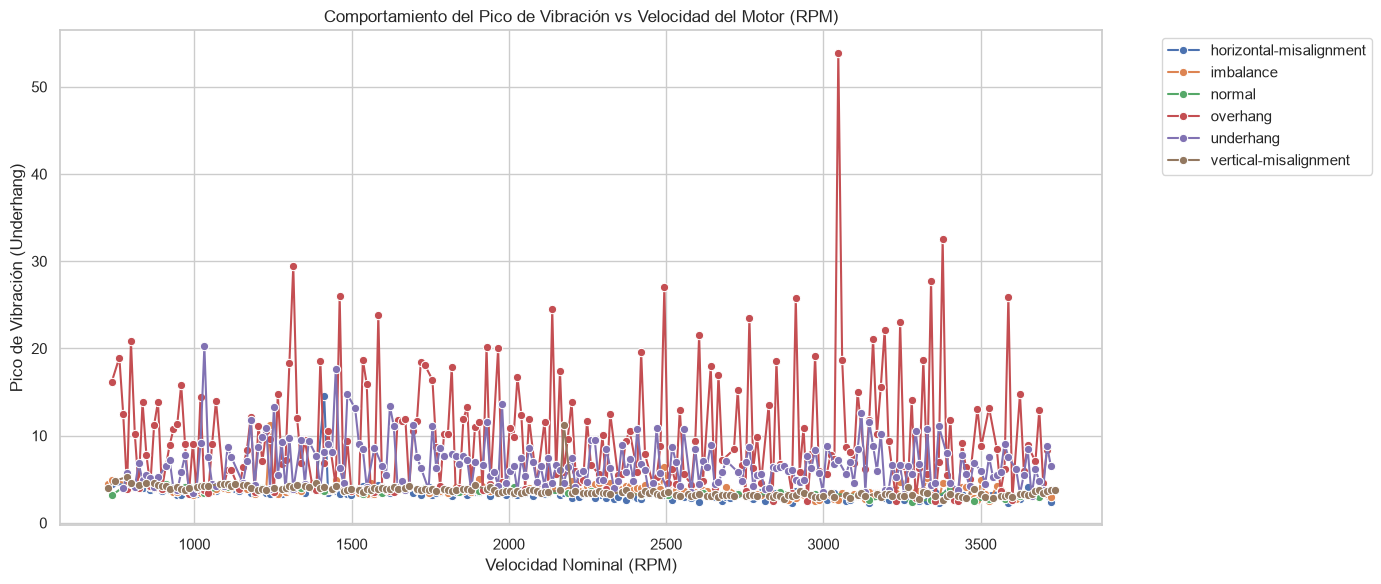

In [8]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='nominal_speed_rpm', y='underhang_axial_peak', hue='fault_family', marker='o', errorbar=None)
plt.title('Comportamiento del Pico de Vibración vs Velocidad del Motor (RPM)')
plt.xlabel('Velocidad Nominal (RPM)')
plt.ylabel('Pico de Vibración (Underhang)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Influencia de las Condiciones de Operación (Velocidad Nominal)
El análisis del comportamiento del pico de vibración frente a la velocidad del motor (RPM) revela que no todas las fallas responden igual a la aceleración. Las fallas de tipo `overhang` y `underhang` muestran una alta volatilidad, generando picos de vibración caóticos y extremos en diferentes rangos de velocidad (destacando un pico anómalo de `overhang` por encima de 50 a ~3100 RPM). Por otro lado, el estado `normal`, el desbalanceo y las desalineaciones mantienen una huella de vibración baja y constante a lo largo de todo el espectro de RPM. Esto sugiere que las características de amplitud máxima son excelentes discriminadores para fallas de "hang", pero ineficientes para separar desalineaciones del estado normal.

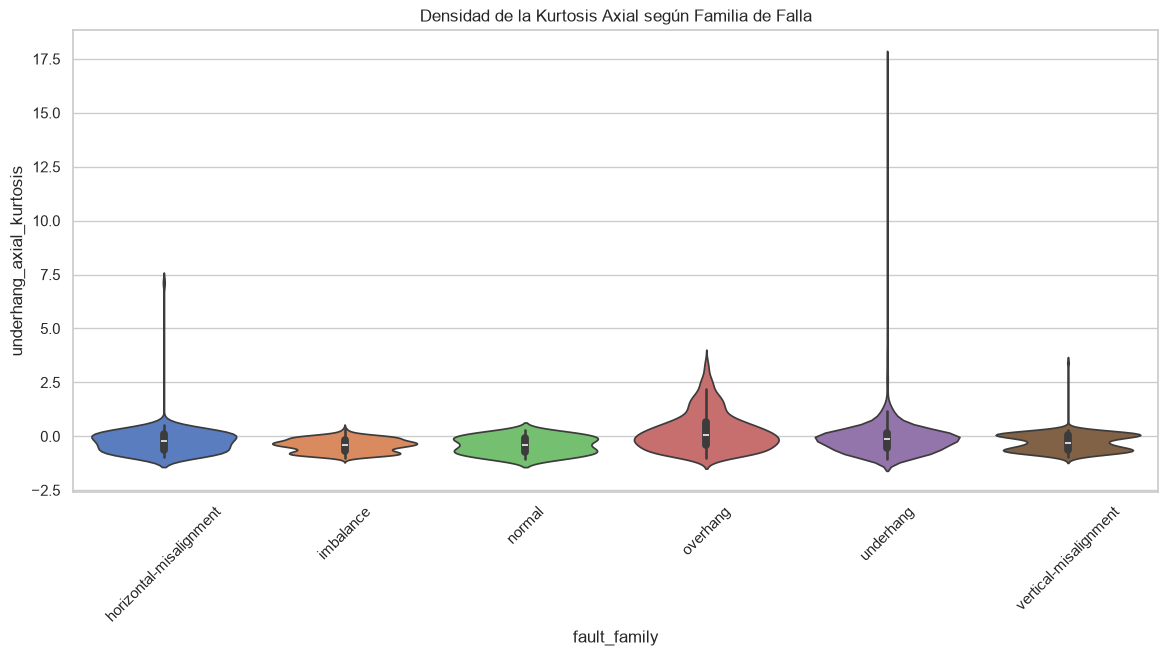

In [9]:
plt.figure(figsize=(14, 6))
sns.violinplot(data=df, x='fault_family', y='underhang_axial_kurtosis', hue='fault_family', palette='muted', legend=False)
plt.title('Densidad de la Kurtosis Axial según Familia de Falla')
plt.xticks(rotation=45)
plt.show()

### Análisis de Densidad (Gráfico de Violín para Kurtosis)
El gráfico de violín revela la distribución real de la Kurtosis Axial en la zona de *underhang*. Mientras que los estados `normal`, `imbalance` y `vertical-misalignment` presentan distribuciones muy concentradas cerca de 0 (indicando señales suaves y sin picos impulsivos), las fallas de tipo `underhang` y `horizontal-misalignment` muestran "colas" superiores extremadamente largas (alcanzando valores cercanos a 17.5 en el caso de `underhang`). 

**Conclusión:** La Kurtosis mide la presencia de impactos agudos en la señal. Este gráfico confirma que la variable `underhang_axial_kurtosis` será un predictor fundamental en el modelo de Machine Learning para detectar los choques impulsivos característicos de los problemas mecánicos graves.